# Distribution of chemical classes along the m/z axis: PN or PU class labels

This notebook analyses where members of chemical classes (lipid classes such as PC, PE or ceramides, and the classes of the other taxonomies) lie on the m/z axis of the model, and whether a position on the binned axis identifies the class. It answers whether a chemical-class head can be trained as a positive/negative (PN) problem — absence of signal in the bins of a class is evidence that the class is absent — or must remain positive/unlabelled (PU) because bins are shared by several classes.

## Introduction

The encoder receives a spectrum binned on a fixed m/z axis (200–900 Da, 0.55 Da bins for the reference models). A class can be detected only through signal in the bins its members occupy. If every bin that a class can occupy is occupied by that class only, the class is a deterministic function of the spectrum, negatives are observable and PN supervision is well defined. If bins are shared, signal in a bin is compatible with several classes; only annotated positives identify the class and unannotated bins are unlabelled, which is the PU setting used by the current molecule heads (VPU).

Two populations are compared:

- **universe** — all compounds of a taxonomy combined with the adducts observed in the collection (`-H`, `+Cl`, `[M]-`) inside the axis range: what *could* appear in a bin;
- **observed** — annotated ions of the collection with exactly one certain class at the given depth: what *did* appear.

### Assumptions

- **Monoisotopic m/z.** Positions are theoretical monoisotopic m/z of formula/adduct ions (METASPACE convention). Isotope peaks, which shift signal by about 1.003 Da into neighbouring bins, are not modelled; they increase sharing at coarse bin widths.
- **Bins.** Bins start at the axis minimum with fixed width; 0.55 Da is the model binning, narrower widths emulate the resolving power available before binning (5 ppm at 500 m/z ≈ 0.0025 Da).
- **Universe counts structures, not abundances.** A bin owned by one class in the universe can still carry no signal in tissue; exclusivity is a necessary, not sufficient, condition for PN labels.
- **Observed labels.** Observed ions use `formula` resolution and certain classes; ions whose class at the depth is ambiguous are excluded from the observed population (they are PU by construction).

### Notation

- $b$ — m/z bin of width $w$; $n_{bc}$ — members of class $c$ in bin $b$; $n_b=\sum_c n_{bc}$; $N=\sum_b n_b$.
- Bayes accuracy $A_w = \sum_b \max_c n_{bc} / N$ — accuracy of the best classifier predicting the class from the bin alone.
- Exclusive fraction of class $c$: $e_c = \sum_{b: n_{bc}=n_b} n_{bc} / \sum_b n_{bc}$; pure fraction $p_c$ uses $n_{bc}/n_b \ge 0.9$.
- Own-class share of an observed ion in bin $b$ with class $c$: $n_{bc}/n_b$ in the universe.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "class_mz_distribution"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:55:54,259 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:55:54,261 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:55:54,668 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:55:54,670 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:55:54,677 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:55:54,679 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:55:54,697 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:55:54,711 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:55:54,713 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis class_mz_distribution


## m/z distribution of chemical classes

### Methodology

#### Theoretical

For each class at the selected taxonomy and depth, the distribution of member m/z values is shown for the universe and for observed ions. Classes concentrated in disjoint m/z ranges can be separated by position alone; classes spanning overlapping ranges cannot, at least without exact mass.

#### Implementation

Theoretical m/z values are computed with the METASPACE neutral-formula/adduct mass convention (`calculate_theoretical_mz`) for every compound of the taxonomy and every adduct of the collection, restricted to the configured axis. Class membership uses the ancestor closure restricted to the given depth (a compound with two classes at a depth counts in both). Histograms use 5 Da bins (`mz_histogram.csv`); quantiles are in `class_mz_quantiles.csv`.

#### Figure descriptions

*Figure 1.* Ridge plot: each row is one class (largest by number of universe members at the top), $x$ is m/z, and the filled profile is the member histogram normalized to its maximum (left panel: universe, right panel: observed ions). Overlap of profiles between rows along $x$ means classes share m/z ranges.

,name,members,observed_ions,q05,q25,q50,q75,q95
8,Fatty Acids and Conjugates,6993,22,214.2,266.2,303.2,357.0,498.4
10,Eicosanoids,4011,4,319.2,351.2,369.2,387.2,461.2
11,Docosanoids,3552,0,357.2,376.2,393.2,411.2,429.2
43,Flavonoids,19036,11,296.1,359.1,445.1,592.1,772.2
14,Fatty esters,5668,10,223.2,293.9,452.4,560.6,795.8
58,Sterols,5420,3,399.2,431.3,475.3,573.4,788.4
45,Isoprenoids,6442,5,220.2,331.1,486.9,595.4,752.6
32,Glycerophosphates,3612,22,576.4,668.4,710.5,748.5,799.5
28,Glycerophosphoethanolamines,4622,13,530.3,708.5,752.6,790.5,839.5
30,Glycerophosphoglycerols,3981,24,675.5,746.5,786.6,822.5,868.6


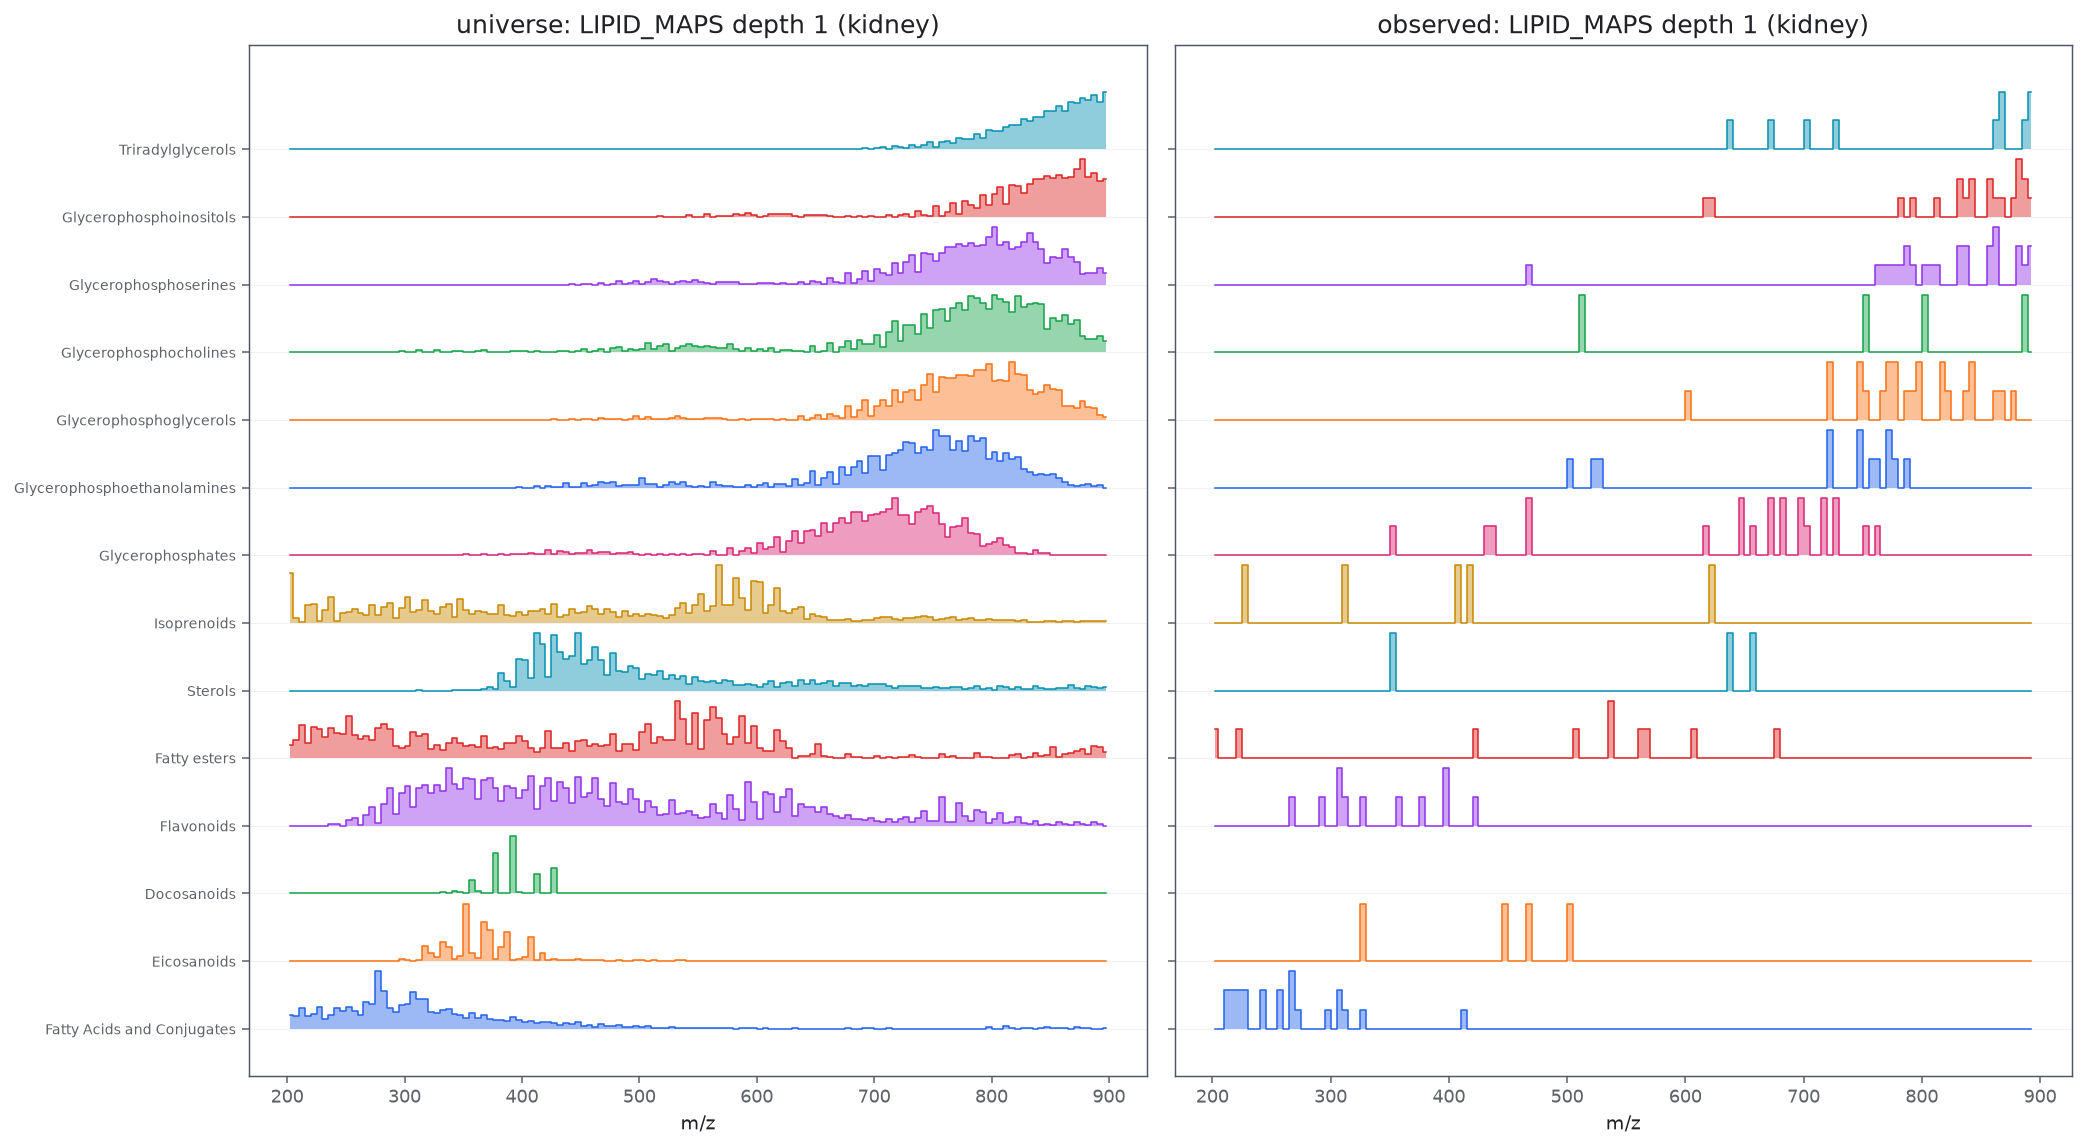

In [2]:
histogram = table("mz_histogram.csv")
quantiles = table("class_mz_quantiles.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
TAXONOMY = "LIPID_MAPS"      # LIPID_MAPS depth 1 = main lipid classes (PC, PE, PI, Cer, ...)
DEPTH = 1
TOP = 14
# ---------------------------------------------------------------------------
rows = quantiles[(quantiles.collection == COLLECTION) & (quantiles.taxonomy == TAXONOMY) & (quantiles.depth == DEPTH)]
selected = rows.nlargest(TOP, "members").sort_values("q50")
names = dict(zip(selected.class_id, selected.name))
subset = histogram[(histogram.collection == COLLECTION) & (histogram.taxonomy == TAXONOMY) & (histogram.depth == DEPTH)]
figure, axes = plt.subplots(1, 2, figsize=(15, 0.45 * TOP + 2), sharey=True)
for axis, population in zip(axes, ["universe", "observed"]):
    plots.mz_class_profiles(axis, subset, list(selected.class_id), names, population=population, theme=THEME)
    axis.set_title(f"{population}: {TAXONOMY} depth {DEPTH} ({COLLECTION})")
plt.tight_layout()
display(selected[["name", "members", "observed_ions", "q05", "q25", "q50", "q75", "q95"]].round(1))

### Remarks

- Glycerophospholipid classes occupy almost the same m/z range in the universe (medians 710–848; PE, PC, PS, PG and PI all between ≈ 680 and 890), and triacylglycerols overlap their upper part. Fatty acyls and eicosanoids lie below 500. Separation by position is therefore only possible between categories, not between phospholipid classes.

### Notes

## Class identifiability from the m/z bin as a function of bin width

### Methodology

#### Theoretical

The Bayes accuracy $A_w$ is the upper bound of any classifier that sees only which bin contains signal; $1 - A_w$ is the irreducible class confusion due to shared bins. The exclusive member fraction $\sum_c \sum_{b: n_{bc}=n_b} n_{bc}/N$ is the share of members that lie in bins owned by a single class: for these members, absence of signal is negative evidence (PN); for the rest it is not (PU). Both are reported for the universe (structural limit) and for observed ions (empirical vocabulary).

Values close to 1 at the model bin width mean that class labels could be supervised as PN; values well below 1 mean that a PU formulation is required for a large share of the class mass.

#### Implementation

Bins are $\lfloor (m/z - 200)/w \rfloor$ for every configured width $w$. Counts $n_{bc}$ are computed for universe members and, separately, for observed ions (`universe_summary.csv`, column `population`). The model width 0.55 Da is marked by a vertical line.

#### Figure descriptions

*Figure 2.* Left: Bayes accuracy $A_w$; right: exclusive member fraction; $x$: bin width (Da, logarithmic); colour: taxonomy; solid line: universe; dashed line: observed ions; one panel row per depth. The dotted vertical line marks the model bin width. Higher values mean the bin identifies the class more reliably; the decrease with $w$ shows how much class information is destroyed by binning.

bayes_accuracy           classes          exclusive_member_fraction         
population                         observed universe observed universe                  observed universe
collection taxonomy    depth                                                                             
brain      ChEBI       0              1.000    1.000      1.0      2.0                     1.000    0.994
                       1              1.000    0.993      1.0      4.0                     1.000    0.154
                       2              1.000    0.570      1.0     22.0                     1.000    0.000
                       3              1.000    0.470      1.0     45.0                     1.000    0.000
           ClassyFire  0              1.000    1.000      1.0      1.0                     1.000    1.000
                       1              1.000    1.000      1.0      2.0                     1.000    0.954
                       2              0.929    0.689      9.0     21.0                     0.851    0.045
                       3              0.873    0.549     36.0    350.0                     0.743    0.000
           LIPID_MAPS  0              0.875    0.646      7.0      7.0                     0.701    0.018
                       1              0.801    0.420     32.0     70.0                     0.634    0.006
                       2              0.833    0.325     60.0    229.0                     0.694    0.002
                       3              1.000    0.378      1.0    175.0                     1.000    0.077
           SwissLipids 0              1.000    0.998      1.0     11.0                     1.000    0.810
                       1              0.892    0.820      5.0      5.0                     0.734    0.030
                       2              0.824    0.564     14.0     38.0                     0.652    0.005
                       3              0.788    0.358     32.0    112.0                     0.596    0.005
kidney     ChEBI       0              1.000    1.000      1.0      2.0                     1.000    0.994
                       1              1.000    0.993      1.0      4.0                     1.000    0.154
                       2              1.000    0.570      1.0     22.0                     1.000    0.000
                       3              1.000    0.470      1.0     45.0                     1.000    0.000
           ClassyFire  0              1.000    1.000      1.0      1.0                     1.000    1.000
                       1              0.998    1.000      2.0      2.0                     0.992    0.954
                       2              0.836    0.689     13.0     21.0                     0.677    0.045
                       3              0.800    0.549     45.0    350.0                     0.643    0.000
           LIPID_MAPS  0              0.895    0.646      6.0      7.0                     0.759    0.018
                       1              0.794    0.420     34.0     70.0                     0.596    0.006
                       2              0.830    0.325     58.0    229.0                     0.667    0.002
                       3              1.000    0.378      3.0    175.0                     1.000    0.077
           SwissLipids 0              1.000    0.998      1.0     11.0                     1.000    0.810
                       1              0.891    0.820      5.0      5.0                     0.748    0.030
                       2              0.819    0.564     19.0     38.0                     0.643    0.005
                       3              0.797    0.358     36.0    112.0                     0.640    0.005

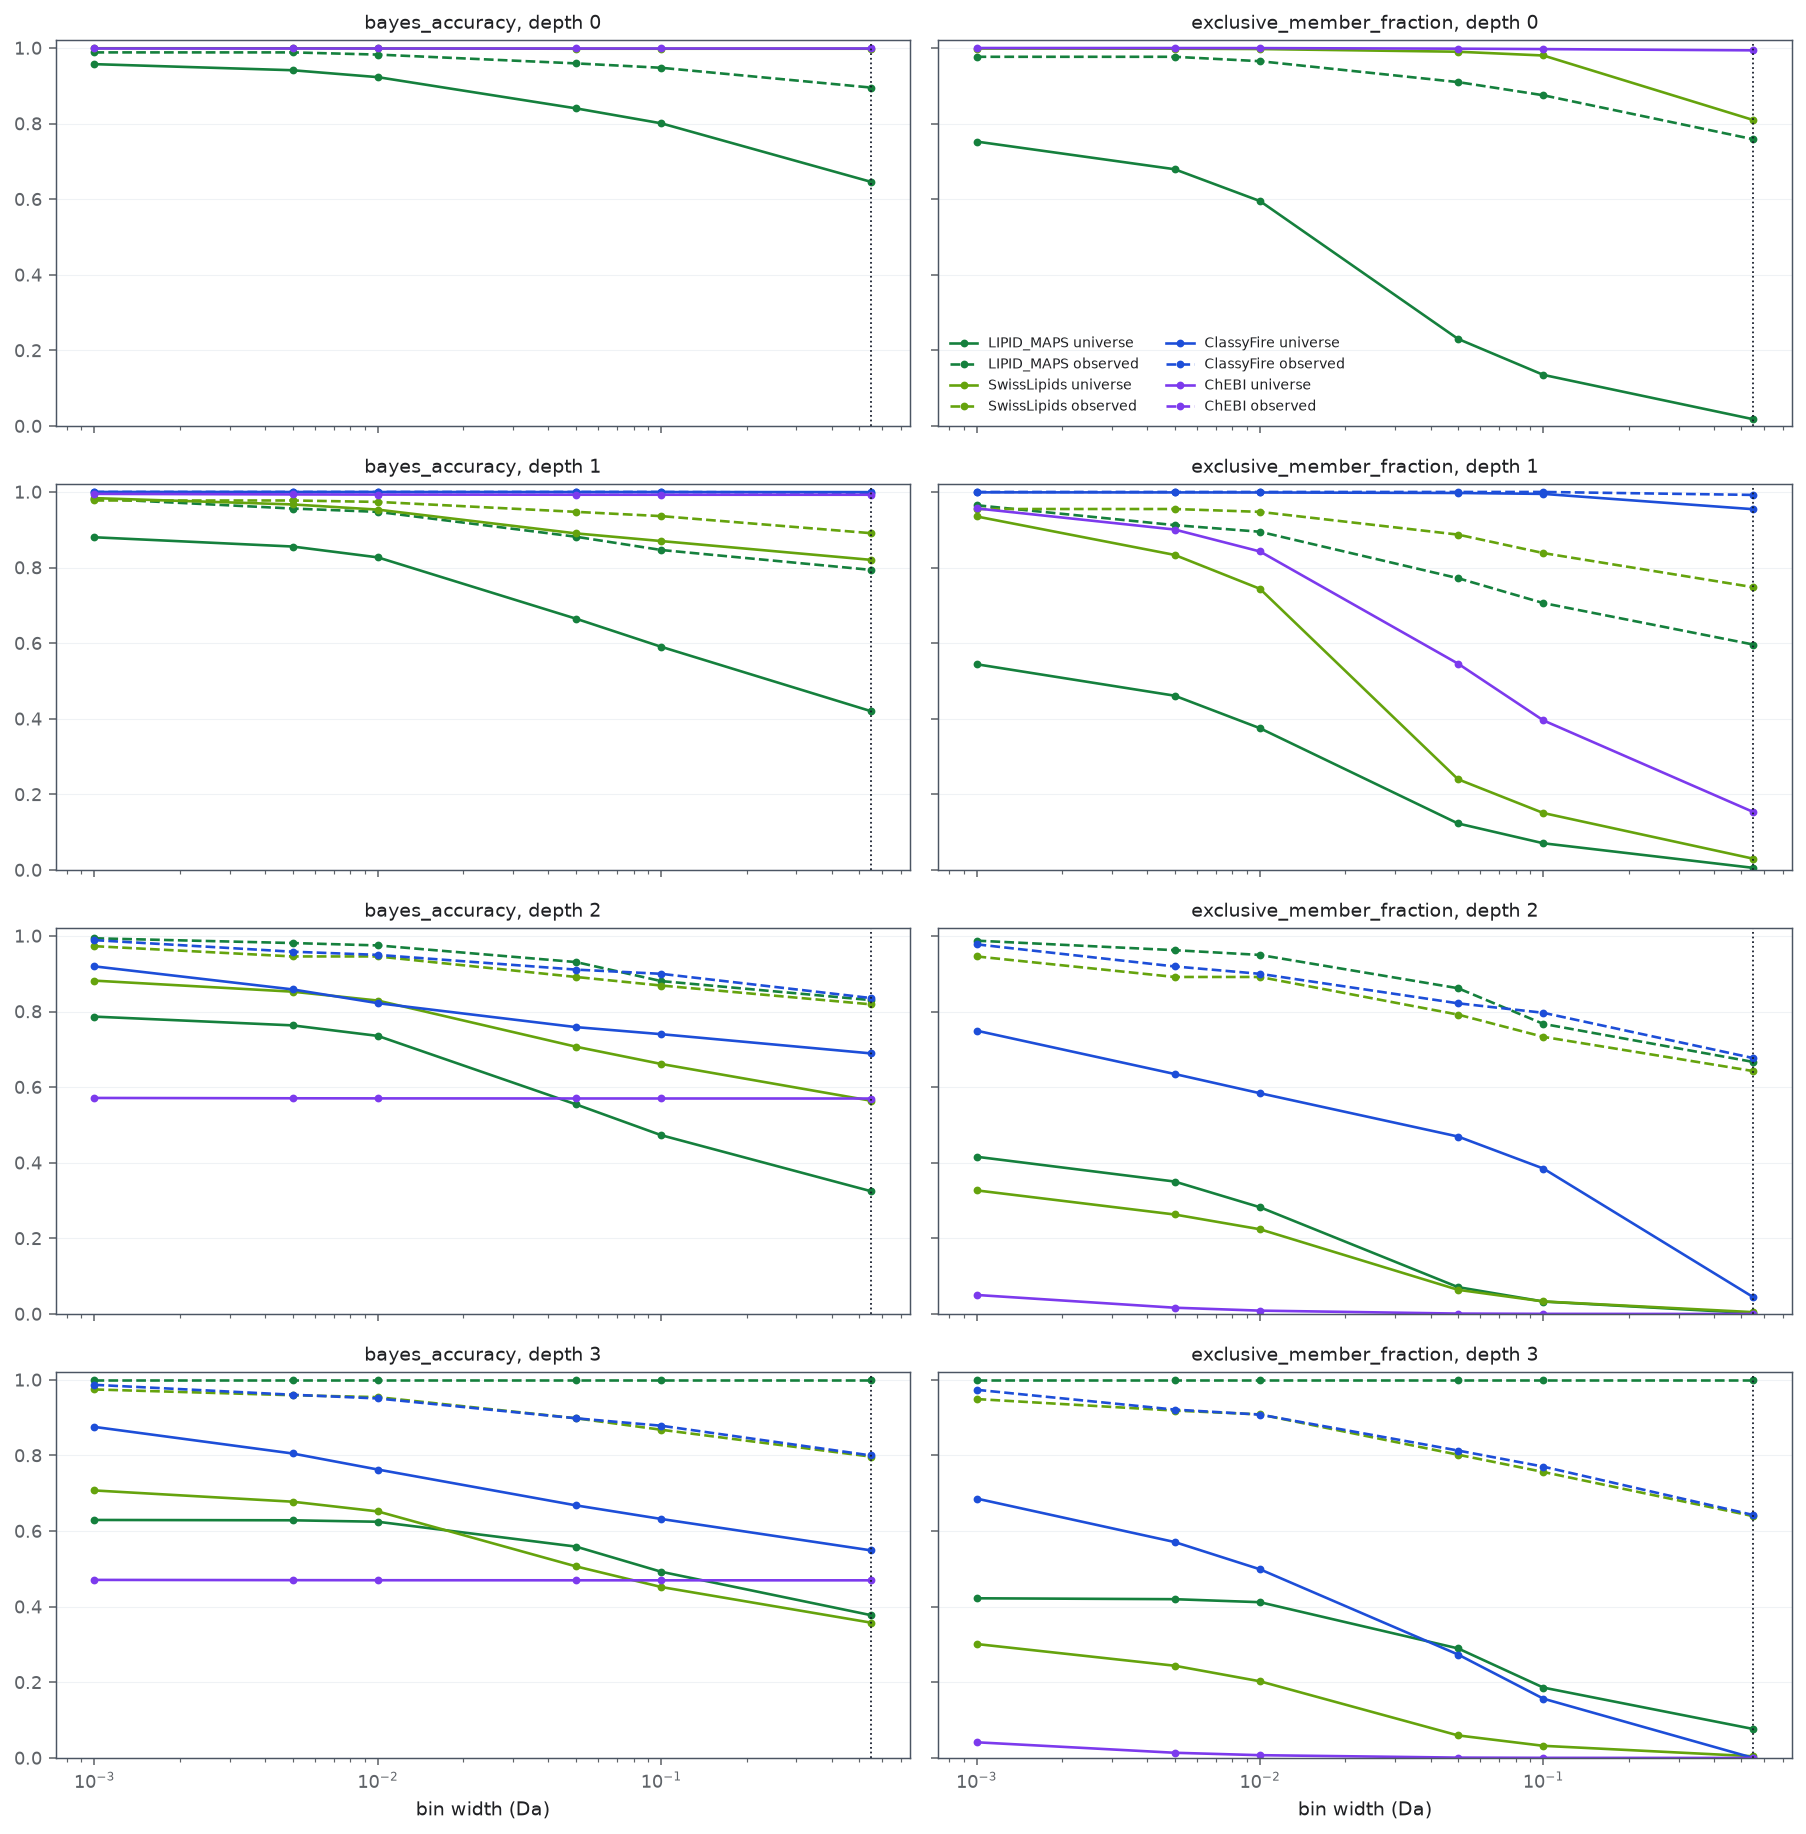

In [3]:
summary_table = table("universe_summary.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
DEPTHS = [0, 1, 2, 3]
MODEL_BIN = 0.55
# ---------------------------------------------------------------------------
figure, axes = plt.subplots(len(DEPTHS), 2, figsize=(13, 3.3 * len(DEPTHS)), sharex=True, sharey=True, squeeze=False)
for row, depth in enumerate(DEPTHS):
    for column, metric in enumerate(["bayes_accuracy", "exclusive_member_fraction"]):
        axis = axes[row, column]
        for taxonomy in TAXONOMIES:
            for population, style in (("universe", "-"), ("observed", "--")):
                rows = summary_table[(summary_table.collection == COLLECTION) & (summary_table.taxonomy == taxonomy)
                                     & (summary_table.depth == depth) & (summary_table.population == population)
                                     & (summary_table.classes > 1)].sort_values("bin_width")
                axis.plot(rows.bin_width, rows[metric], style, marker="o", markersize=3,
                          color=plots.taxonomy_color(taxonomy), label=f"{taxonomy} {population}")
        axis.axvline(MODEL_BIN, color=THEME.baseline_color, linestyle=":", linewidth=THEME.reference_line_width)
        axis.set_xscale("log")
        axis.set_ylim(0, 1.02)
        axis.set_title(f"{metric}, depth {depth}", fontsize=10)
axes[-1, 0].set_xlabel("bin width (Da)")
axes[-1, 1].set_xlabel("bin width (Da)")
axes[0, 1].legend(fontsize=7, frameon=False, ncols=2)
plt.tight_layout()
display(summary_table[(summary_table.bin_width == MODEL_BIN) & summary_table.depth.isin(DEPTHS)]
        .pivot_table(index=["collection", "taxonomy", "depth"], columns="population",
                     values=["classes", "bayes_accuracy", "exclusive_member_fraction"]).round(3))

### Remarks

- At 0.55 Da the universe exclusive member fraction is ≤ 0.08 for LIPID MAPS and ClassyFire at every depth with more than two classes and ≤ 0.03 for SwissLipids below depth 0 (LIPID MAPS main classes 0.006). SwissLipids depth 0 (0.81) is an artefact: it mixes the `Lipid` root with ≈ 300 classes that SwissLipids does not link to any parent; ChEBI depth 1 retains 0.15–0.22 only because its four depth-1 classes are extremely coarse; Bayes accuracy of the LIPID MAPS main class is 0.42 (universe) and 0.79 (observed vocabulary).
- ChEBI Bayes accuracy is flat (≈ 0.57 at depth 2) across widths because compounds belong to several classes at the same depth; with multi-membership the metric is bounded by the number of classes per compound, not by m/z resolution.
- The observed curves are computed only among co-annotated classes and are therefore vocabulary dependent.

### Notes

## Exclusivity of individual classes at the model bin width

### Methodology

#### Theoretical

The per-class exclusive fraction $e_c$ and pure fraction $p_c$ show which classes own their bins. A class with $e_c \approx 1$ can be supervised as PN even if other classes cannot; a mixed formulation (PN for exclusive classes, PU for shared ones) is possible. `classes_sharing_bins` counts the distinct classes co-occurring with $c$ in at least one bin and identifies the confusable partners.

#### Implementation

`universe_classes.csv` at the selected width and depth, restricted to classes with at least the configured number of universe members. Lipid classes are read from LIPID MAPS (depth 1 = main class) and SwissLipids.

#### Figure descriptions

*Figure 3.* Violins of the per-class exclusive fraction $e_c$ over classes ($y$) for each taxonomy ($x$) at a comparable class level per taxonomy (LIPID MAPS main class = depth 1, SwissLipids class = depth 2, ClassyFire class = depth 3, ChEBI depth 3; depths are not comparable across taxonomies) and the selected bin width; each point is one class. Higher values mean classes whose bins identify them. The table lists the selected taxonomy's classes ordered by $e_c$.

,name,members,exclusive_fraction,pure_fraction,classes_sharing_bins
438,Flavonoids,19036.0,0.029,0.120,69
429,Halogenated acetogenins,45.0,0.022,0.022,35
403,Hydrocarbons,1634.0,0.020,0.067,54
404,Oxygenated hydrocarbons,644.0,0.005,0.005,46
397,Fatty alcohols,921.0,0.003,0.003,53
393,Fatty Acids and Conjugates,6993.0,0.003,0.003,63
450,Ceramides,1308.0,0.002,0.002,63
399,Fatty esters,5668.0,0.001,0.003,64
441,Isoprenoids,6442.0,0.000,0.000,69
396,Docosanoids,3552.0,0.000,0.000,50


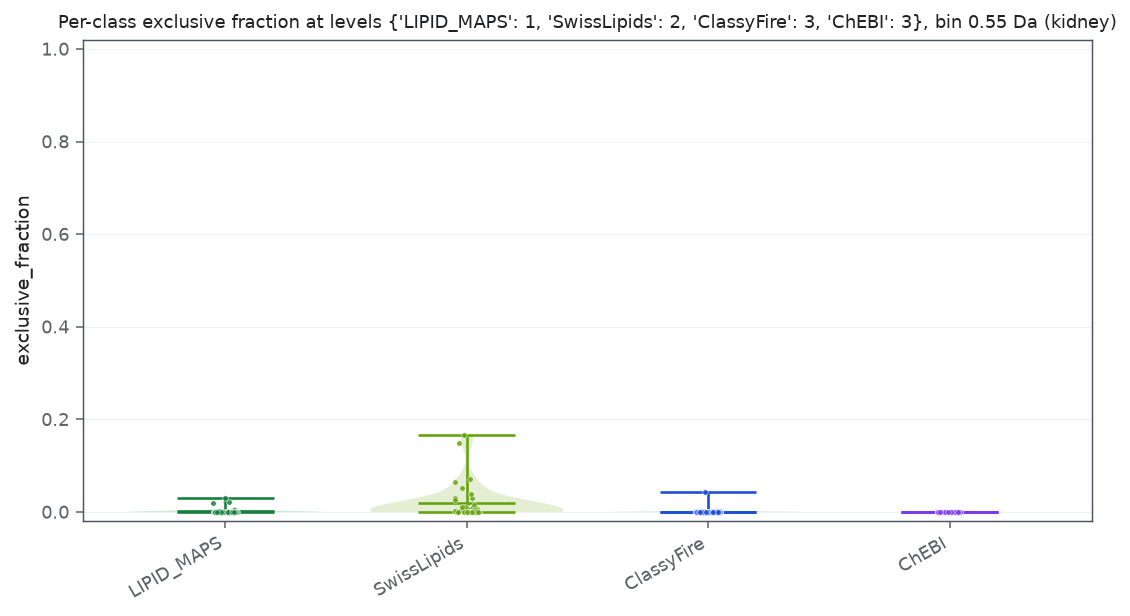

In [4]:
per_class = table("universe_classes.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
LEVELS = {"LIPID_MAPS": 1, "SwissLipids": 2, "ClassyFire": 3, "ChEBI": 3}   # comparable "class" level per taxonomy
BIN_WIDTH = 0.55
MIN_MEMBERS = 20
TABLE_TAXONOMY = "LIPID_MAPS"
# ---------------------------------------------------------------------------
subset = per_class[(per_class.collection == COLLECTION) & (per_class.depth == per_class.taxonomy.map(LEVELS))
                   & np.isclose(per_class.bin_width, BIN_WIDTH) & (per_class.members >= MIN_MEMBERS)]
figure, axis = plt.subplots(figsize=(8, 4.5))
plots.violin_groups(axis, subset, group="taxonomy", value="exclusive_fraction", order=TAXONOMIES,
                    colors={t: plots.taxonomy_color(t) for t in TAXONOMIES}, theme=THEME)
axis.set_ylim(-0.02, 1.02)
axis.set_title(f"Per-class exclusive fraction at levels {LEVELS}, bin {BIN_WIDTH} Da ({COLLECTION})", fontsize=9)
plt.tight_layout()
display(subset[subset.taxonomy == TABLE_TAXONOMY].sort_values("exclusive_fraction", ascending=False)
        [["name", "members", "exclusive_fraction", "pure_fraction", "classes_sharing_bins"]].round(3))

### Remarks

- No LIPID MAPS main class owns its bins at 0.55 Da (largest exclusive fraction: flavonoids 0.03); every lipid class shares bins with 26–69 other classes.

### Notes

## Observed ions in exclusive and shared bins

### Methodology

#### Theoretical

For every observed ion with a unique certain class $c$ at the depth, the own-class share $n_{bc}/n_b$ of its bin in the universe is computed. A share of 1 means that any signal in that bin can only come from class $c$ (among structures known to the taxonomy), so the label of that bin can be treated as PN. A share below 1 means that the bin also hosts other classes and the absence of the annotation does not imply absence of $c$ (PU).

The PN-eligible fraction is the share of observed ions with own-class share equal to 1.

#### Implementation

`observed_ions.csv` joins each observed ion with the universe counts of its bin at each width. The PN-eligible fraction is aggregated per collection, taxonomy, depth and width.

#### Figure descriptions

*Figure 4.* Violins of the own-class share ($y$) over observed ions, per taxonomy ($x$), at the same per-taxonomy class levels as Figure 3 and the model bin width; each point is an annotated ion. Values at 1 are PN-eligible ions; values near 0 are ions whose bin is dominated by other classes. The table reports the PN-eligible fraction for all widths.

bin_width                     0.001  0.005  0.010  0.050  0.100  0.550
collection taxonomy    depth                                          
brain      ChEBI       0      0.995  0.998  1.000  1.000  1.000  0.998
                       1      0.985  0.977  0.964  0.836  0.729  0.435
                       2      0.224  0.164  0.137  0.016  0.005  0.000
                       3      0.156  0.114  0.095  0.011  0.004  0.000
                       4      0.017  0.017  0.011  0.000  0.000  0.000
                       5      0.016  0.016  0.011  0.000  0.000  0.000
           ClassyFire  0      0.998  0.998  0.998  0.998  1.000  1.000
                       1      0.998  0.998  0.998  0.998  0.998  0.959
                       2      0.927  0.766  0.673  0.443  0.310  0.038
                       3      0.847  0.651  0.524  0.201  0.093  0.000
                       4      0.825  0.579  0.428  0.054  0.013  0.000
                       5      0.855  0.675  0.490  0.075  0.030  0.000
           LIPID_MAPS  0      0.836  0.705  0.586  0.139  0.050  0.004
                       1      0.847  0.591  0.398  0.037  0.023  0.003
                       2      0.845  0.571  0.361  0.036  0.020  0.000
                       3      1.000  1.000  1.000  0.000  0.000  0.000
           SwissLipids 0      1.000  1.000  1.000  0.990  0.980  0.875
                       1      0.915  0.817  0.767  0.236  0.123  0.023
                       2      0.885  0.669  0.507  0.047  0.027  0.007
                       3      0.873  0.700  0.531  0.054  0.031  0.012
                       4      1.000  1.000  1.000  1.000  1.000  0.000
kidney     ChEBI       0      0.994  0.997  0.998  0.998  1.000  0.998
                       1      0.978  0.943  0.892  0.604  0.483  0.220
                       2      0.112  0.042  0.038  0.004  0.000  0.000
                       3      0.093  0.035  0.032  0.003  0.000  0.000
                       4      0.024  0.005  0.000  0.000  0.000  0.000
                       5      0.021  0.004  0.000  0.000  0.000  0.000
           ClassyFire  0      0.996  0.998  0.998  0.998  1.000  1.000
                       1      0.996  0.998  0.996  0.996  0.990  0.914
                       2      0.852  0.543  0.435  0.231  0.167  0.025
                       3      0.820  0.495  0.377  0.141  0.082  0.000
                       4      0.788  0.408  0.276  0.064  0.032  0.000
                       5      0.848  0.506  0.323  0.079  0.018  0.000
           LIPID_MAPS  0      0.913  0.828  0.735  0.145  0.038  0.009
                       1      0.904  0.654  0.491  0.026  0.009  0.000
                       2      0.893  0.673  0.491  0.038  0.019  0.000
                       3      1.000  1.000  1.000  0.500  0.500  0.250
           SwissLipids 0      1.000  1.000  1.000  0.996  0.982  0.908
                       1      0.891  0.816  0.752  0.376  0.226  0.049
                       2      0.869  0.692  0.570  0.145  0.086  0.023
                       3      0.848  0.706  0.599  0.142  0.086  0.030
                       4      1.000  1.000  1.000  1.000  1.000  0.000

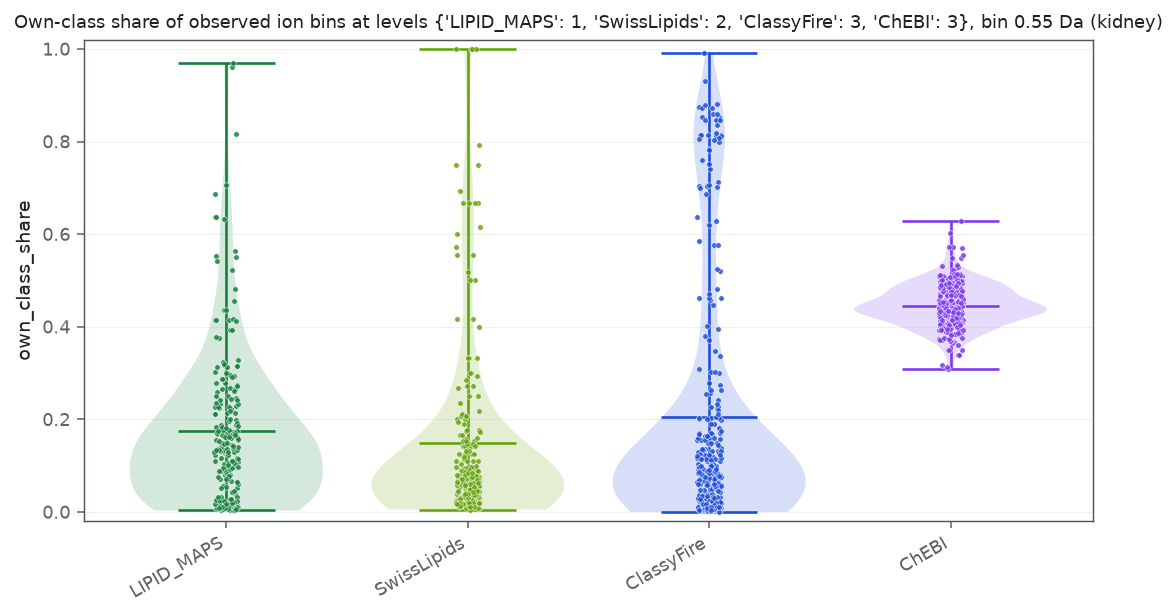

In [5]:
observed = table("observed_ions.csv")

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
LEVELS = {"LIPID_MAPS": 1, "SwissLipids": 2, "ClassyFire": 3, "ChEBI": 3}
BIN_WIDTH = 0.55
# ---------------------------------------------------------------------------
subset = observed[(observed.collection == COLLECTION) & (observed.depth == observed.taxonomy.map(LEVELS))
                  & np.isclose(observed.bin_width, BIN_WIDTH)]
figure, axis = plt.subplots(figsize=(8, 4.5))
plots.violin_groups(axis, subset, group="taxonomy", value="own_class_share", order=TAXONOMIES,
                    colors={t: plots.taxonomy_color(t) for t in TAXONOMIES}, theme=THEME)
axis.set_ylim(-0.02, 1.02)
axis.set_title(f"Own-class share of observed ion bins at levels {LEVELS}, bin {BIN_WIDTH} Da ({COLLECTION})", fontsize=9)
plt.tight_layout()
eligibility = (observed.assign(pn_eligible=np.isclose(observed.own_class_share, 1.0))
               .groupby(["collection", "taxonomy", "depth", "bin_width"]).pn_eligible.mean().unstack("bin_width"))
display(eligibility.round(3))

### Remarks

- PN-eligible fraction of observed LIPID MAPS main-class ions (bin owned by the ion's class in the universe) is 0.000 at 0.55 Da but 0.90 (kidney) / 0.85 (brain) at 0.001 Da: class information is present in exact mass and destroyed by the model binning.

### Notes

## Results / Summary

### LLM

**Observed.** At the model bin width (0.55 Da) almost no bin is owned by a single chemical class among all structures of a taxonomy (exclusive member fraction ≤ 0.08 for LIPID MAPS, SwissLipids and ClassyFire at every non-trivial depth; 0.006 for LIPID MAPS main classes). Within the annotated vocabulary only, 60–85 % of ions lie in bins not shared with another annotated class. At 1 mDa, 85–90 % of observed lipid-class ions are in bins owned by their class.

**Interpretation for PU vs PN.** For binned spectra, chemical-class labels are structurally **PU**: signal in a bin is compatible with several classes and absence of annotation is not absence of the class. A PN treatment is defensible only conditionally — for classes and bins verified exclusive under the observed vocabulary (≈ 60–85 % of observed ions) — and inherits the incompleteness of that vocabulary. Exact mass largely identifies the class; the loss is caused by 0.55 Da binning, so class supervision would profit from finer m/z resolution more than from a different loss.

**Caveats.** The universe contains every taxonomy structure (including computationally enumerated lipids and plant metabolites), which overstates sharing relative to tissue; isotope peaks (+1.003 Da) are not modelled and would add sharing at coarse widths. Multi-membership DAGs (ChEBI) cap the Bayes accuracy independently of m/z.

### Person